# Notebook 6 — Combining LNDb and LIDC-IDRI: Final Model and Competition Predictions
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

---

## The question
Notebook 4 trained malignancy models on ~765 LNDb nodules. Notebook 5 prepared ~1630 more nodules from
**LIDC-IDRI**, rated on the same 1–5 scale and described by exactly the same 1136 features — but from
another country, other scanners, other radiologists and a much more malignant population. **Does
that extra data help a model that will be used on LNDb?** Three routes, evaluated on the **same
4 official LNDb folds** as Notebook 4:

| Route | Trained on | Story |
|---|---|---|
| **LNDb only** | LNDb training folds | Notebook 4 (score committee, and the SVM classifier) |
| **LIDC only** | All of LIDC-IDRI, never LNDb | What we submitted before finding LNDb's malignancy ratings |
| **LNDb + LIDC** | LNDb training folds **plus** all of LIDC-IDRI | LIDC as extra training data |

LIDC nodules only ever **add** training data: they are never in a test fold, so every number below
measures performance **on LNDb nodules**, the competition's population.

**Inputs:** `outputs/features_train.csv`, `outputs/features_test.csv` (Notebook 2), `outputs/working_dataset.csv`
(Notebook 1), `outputs/selected_features.json` (Notebook 3), `outputs/lndb_cv_predictions.csv` (Notebook 4),
`outputs/features_lidc.csv` (Notebook 5)
**Outputs:** `outputs/malignancy_model_final.joblib`, **`outputs/predictions.csv`** (competition file)

> ⏱️ Run time: ~30–45 minutes on an 8-core laptop.

---

## 1. Setup

In [1]:
import json
import shutil
import tempfile
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Memory
from scipy.stats import spearmanr
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score, mean_absolute_error

import lndb_utils as U
import lndb_models as M

for w in (UserWarning, RuntimeWarning, FutureWarning, ConvergenceWarning, pd.errors.PerformanceWarning):
    warnings.filterwarnings('ignore', category=w)
plt.rcParams.update(U.PLOT_STYLE)

N_JOBS = -1
LABELS = U.MAL_LABELS
METRICS = ['Balanced acc.', 'Macro F1', 'QWK', 'MAE']
CACHE_DIR = tempfile.mkdtemp(prefix='lndb_nb6_')
memory = Memory(CACHE_DIR, verbose=0)


def competition_metrics(y_true, y_pred) -> dict:
    return {'Balanced acc.': balanced_accuracy_score(y_true, y_pred),
            'Macro F1': f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0),
            'QWK': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
            'MAE': mean_absolute_error(y_true, y_pred)}

print('Setup complete.')

Setup complete.


## 2. Load the data

In [2]:
keys = ['LNDbID', 'FindingID']
labels = pd.read_csv(U.OUTPUT_DIR / 'working_dataset.csv')
label_cols = ['malignancy_mean', 'malignancy_class', 'malignancy_ratings', 'fold']
lndb = pd.read_csv(U.OUTPUT_DIR / 'features_train.csv')
lndb = lndb.drop(columns=[c for c in label_cols if c in lndb.columns]).merge(labels[keys + label_cols], on=keys)
lndb = lndb.dropna(subset=['malignancy_mean']).reset_index(drop=True)
lidc = pd.read_csv(U.OUTPUT_DIR / 'features_lidc.csv')
selection = json.loads((U.OUTPUT_DIR / 'selected_features.json').read_text())
nb4 = pd.read_csv(U.OUTPUT_DIR / 'lndb_cv_predictions.csv')

features = [c for c in lndb.columns if c.startswith(('rad_', 'comp_'))]
assert features == [c for c in lidc.columns if c.startswith(('rad_', 'comp_'))]
assert (nb4[keys].values == lndb[keys].values).all(), 'Notebook 4 must be run on the same nodules first.'

X, s, y = lndb[features].values, lndb.malignancy_mean.values, lndb.malignancy_class.astype(int).values
g, fold = lndb.LNDbID.astype(str).values, lndb.fold.values
XL, sL = lidc[features].values, lidc.malignancy_mean.values
gL = ('LIDC-' + lidc.patient_id.astype(str)).values        # LIDC patients, never mixed with LNDb CTs
FOLDS = sorted(np.unique(fold))

dist = pd.DataFrame({'LNDb': pd.Series(y).value_counts(normalize=True),
                     'LIDC-IDRI': lidc.malignancy_class.value_counts(normalize=True)}).reindex(LABELS)
print(f'LNDb nodules: {len(lndb)}   LIDC-IDRI nodules: {len(lidc)}   features: {len(features)}')
dist.style.format('{:.0%}').set_caption('Malignancy classes in the two datasets')

LNDb nodules: 765   LIDC-IDRI nodules: 1633   features: 1136


,LNDb,LIDC-IDRI
1,28%,10%
2,33%,21%
3,27%,45%
4,9%,19%
5,2%,5%


**Two very different populations.** LNDb (a hospital population, many incidental nodules) is mostly
benign: ~60% of its nodules are rated 1–2. Our LIDC-IDRI download is centred on 3 and has far more 4s
and 5s (it was chosen to include malignant nodules — Notebook 5). A model trained on LIDC alone learns
LIDC's idea of "typical", and its cut-offs reproduce LIDC's proportions.

## 3. The three routes, on the same folds
All routes use the **score committee** of Notebook 4 (KNN + SVR + MLP regressors on the average rating,
prevalence cut-offs). What changes is the training data, and — for the combined route — two choices:

- **Whose proportions set the cut-offs?** Prevalence matching reproduces the class proportions of the
  training data. With LIDC in the training set, those would be LIDC's (too malignant for LNDb), so the
  cut-offs are computed on the **LNDb part only** (its out-of-fold scores inside the training folds).
- **How much does each LNDb nodule count?** LNDb nodules are the population we predict for, LIDC
  nodules are "foreign" examples. We test LNDb nodules counting **1×** and **3×** as much as a LIDC
  nodule (sample weights).

In [3]:
def committee():
    return M.TextureScoreCommittee(selection=selection, class_thresholds=U.MAL_THRESHOLDS, half_up=True,
                                   cutoffs='prevalence', n_jobs=N_JOBS, memory=memory)


def fit_combined(tr, w_lndb):
    """Committee on LNDb (rows `tr`) + all LIDC; cut-offs from the LNDb part only."""
    n = tr.sum()
    m = committee().fit(np.vstack([X[tr], XL]), np.r_[s[tr], sL], np.r_[g[tr], gL],
                        sample_weight=np.r_[np.full(n, float(w_lndb)), np.ones(len(sL))])
    oof_lndb = np.mean(list(m.oof_scores_.values()), axis=0)[:n]
    m.thresholds_ = M.prevalence_thresholds(oof_lndb, y[tr] - 1, n_classes=5)
    return m


pred = {'SVM, LNDb only (Notebook 4)': nb4.SVM.values, 'LNDb only (Notebook 4)': nb4.committee.values}
scores = {'LNDb only (Notebook 4)': nb4.committee_score.values}

# LIDC only: one model, never sees LNDb
m_lidc = committee().fit(XL, sL, gL)
scores['LIDC only'] = m_lidc.predict_score(X)
pred['LIDC only'] = M.score_to_class(scores['LIDC only'], m_lidc.thresholds_, half_up=True) + 1

for w in [1, 3]:
    name = f'LNDb + LIDC (LNDb ×{w})'
    pred[name], scores[name] = np.zeros(len(y), dtype=int), np.zeros(len(y))
    for f in FOLDS:
        tr, te = fold != f, fold == f
        m = fit_combined(tr, w)
        scores[name][te] = m.predict_score(X[te])
        pred[name][te] = M.score_to_class(scores[name][te], m.thresholds_, half_up=True) + 1
    print(f'{name}: done')

LNDb + LIDC (LNDb ×1): done
LNDb + LIDC (LNDb ×3): done


## 4. Which route wins?

In [4]:
pairs = []
for r in lndb.malignancy_ratings.astype(str):
    v = [int(x) for x in r.split(',') if x and x != 'nan']
    pairs += [(v[i], v[j]) for i in range(len(v)) for j in range(i + 1, len(v))]
pairs = np.array(pairs)

table = pd.DataFrame({k: competition_metrics(y, p) for k, p in pred.items()}).T
table['Spearman ρ (score)'] = [spearmanr(scores[k], s)[0] if k in scores else np.nan for k in table.index]
ranks = pd.concat([table[m].rank(ascending=(m == 'MAE')) for m in METRICS], axis=1)
table['mean rank'] = ranks.mean(axis=1)
table.loc['Radiologist vs radiologist'] = list(competition_metrics(pairs[:, 0], pairs[:, 1]).values()) + [np.nan, np.nan]
table.style.format({**{m: '{:.3f}' for m in METRICS}, 'Spearman ρ (score)': '{:.3f}', 'mean rank': '{:.2f}'}, na_rep='—')

,Balanced acc.,Macro F1,QWK,MAE,Spearman ρ (score),mean rank
"SVM, LNDb only (Notebook 4)",0.455,0.407,0.487,0.754,—,3.00
LNDb only (Notebook 4),0.384,0.383,0.525,0.689,0.545,4.00
LIDC only,0.388,0.389,0.451,0.740,0.459,4.25
LNDb + LIDC (LNDb ×1),0.422,0.416,0.554,0.673,0.585,1.75
LNDb + LIDC (LNDb ×3),0.412,0.406,0.557,0.663,0.581,2.00
Radiologist vs radiologist,0.445,0.411,0.527,0.790,—,—


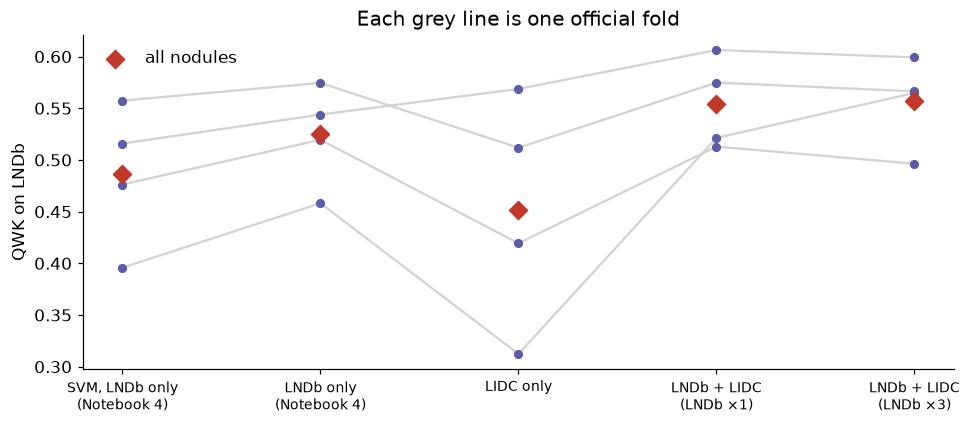

,"SVM, LNDb only (Notebook 4)",LNDb only (Notebook 4),LIDC only,LNDb + LIDC (LNDb ×1),LNDb + LIDC (LNDb ×3)
fold 0,0.516,0.544,0.569,0.606,0.599
fold 1,0.476,0.519,0.419,0.513,0.496
fold 2,0.557,0.574,0.512,0.575,0.566
fold 3,0.396,0.458,0.312,0.521,0.565


In [5]:
fold_qwk = pd.DataFrame({k: [cohen_kappa_score(y[fold == f], p[fold == f], weights='quadratic') for f in FOLDS]
                         for k, p in pred.items()}, index=[f'fold {f}' for f in FOLDS])
fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(pred))
for f in fold_qwk.index:
    ax.plot(xs, fold_qwk.loc[f].values, color='lightgray', zorder=1)
    ax.scatter(xs, fold_qwk.loc[f].values, color=U.COLOR_NEUTRAL, s=25, zorder=2)
ax.scatter(xs, table.loc[list(pred), 'QWK'], marker='D', s=70, color=U.COLOR_ACCENT, zorder=3, label='all nodules')
ax.set_xticks(xs, [k.replace(' (', '\n(') for k in pred], fontsize=9)
ax.set(ylabel='QWK on LNDb', title='Each grey line is one official fold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
fold_qwk.round(3)

**Reading the results.**
- **LIDC alone is the weakest route** (QWK 0.45): worse than every LNDb-trained model, and in two
  folds much worse (0.31–0.42). Our early competition submissions, built this way, were limited by
  this — not by the choice of algorithm.
- **LNDb alone** is at the level of two radiologists (QWK 0.53, Notebook 4).
- **LNDb + LIDC is the best route** — first on QWK, macro F1 and MAE and on mean rank (only the SVM
  classifier has a higher balanced accuracy), and better than the LNDb-only committee in 3 of 4 folds.
  LIDC adds what LNDb lacks: hundreds of nodules rated 4–5.
- **LNDb weighted 1× or 3×?** The two variants are practically tied (QWK 0.554 vs 0.557, MAE 0.67 vs
  0.66, balanced accuracy 0.42 vs 0.41); 1× has the higher QWK in 3 of 4 folds, 3× the higher pooled QWK. The competition's rule (mean rank)
  picks **1×** in this run; on another computer (different floating-point rounding in the MLP) it picked
  3× — a reminder that differences of 0.01 are noise.
- **The final model is above radiologist-vs-radiologist agreement** on QWK (0.55 vs 0.53), macro F1
  and MAE (0.67 vs 0.79), and close on balanced accuracy.

The difference between the two combined variants is noise; the difference between using LNDb labels
or not (≈ 0.10 QWK over LIDC only) is large and consistent.

## 5. Why does LIDC alone transfer so poorly?
The LIDC-only model was the basis of our earlier submissions. Now that LNDb has malignancy labels, we
can measure exactly where it goes wrong:

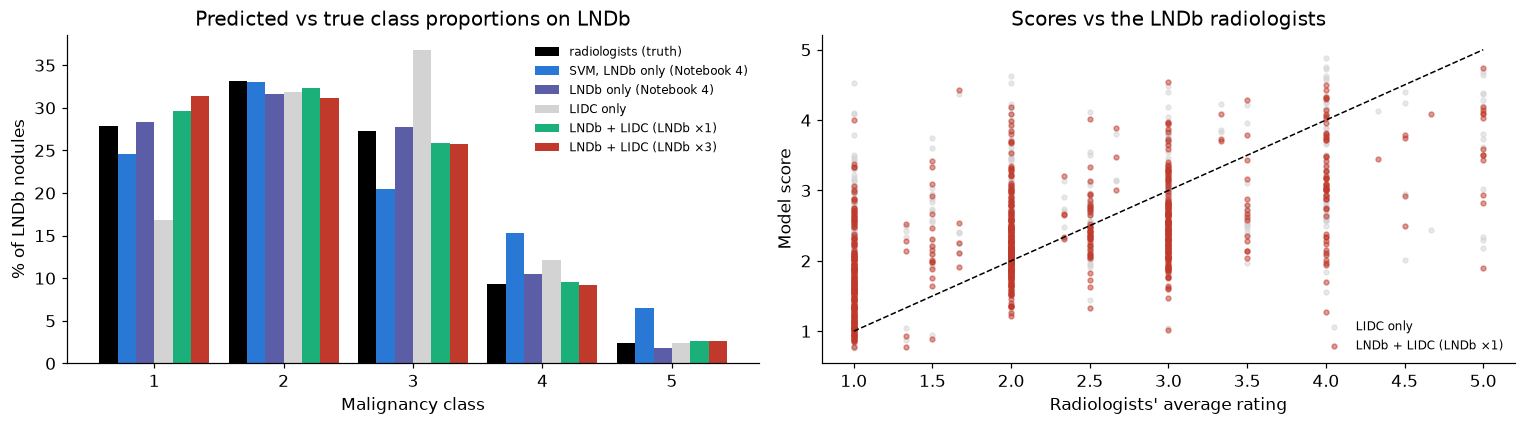

Mean score on LNDb nodules — radiologists: 2.20 | LIDC only: 2.52 | LNDb + LIDC (LNDb ×1): 2.30


In [6]:
pdist = pd.DataFrame({k: pd.Series(p).value_counts(normalize=True) for k, p in pred.items()}).reindex(LABELS).fillna(0)
pdist.insert(0, 'radiologists (truth)', pd.Series(y).value_counts(normalize=True).reindex(LABELS))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pdist.mul(100).plot.bar(ax=axes[0], rot=0, width=0.85,
                        color=['black', U.SOURCE_COLORS['original'], U.COLOR_NEUTRAL, 'lightgray', U.SOURCE_COLORS['LoG'], U.COLOR_ACCENT])
axes[0].set(xlabel='Malignancy class', ylabel='% of LNDb nodules', title='Predicted vs true class proportions on LNDb')
axes[0].legend(frameon=False, fontsize=8)
best = table.drop(['Radiologist vs radiologist', 'SVM, LNDb only (Notebook 4)'])['mean rank'].idxmin()
for k, col in [('LIDC only', 'lightgray'), (best, U.COLOR_ACCENT)]:
    axes[1].scatter(s, scores[k], s=10, alpha=0.5, color=col, label=k)
axes[1].plot([1, 5], [1, 5], color='black', lw=1, ls='--')
axes[1].set(xlabel="Radiologists' average rating", ylabel='Model score', title='Scores vs the LNDb radiologists')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print('Mean score on LNDb nodules — radiologists: {:.2f} | LIDC only: {:.2f} | {}: {:.2f}'.format(
    s.mean(), scores['LIDC only'].mean(), best, scores[best].mean()))

**Reading it.** The LIDC-only model predicts too few 1s (17% vs 28%) and too many 3s (37% vs 27%):
its scores are shifted upwards (mean 2.52 vs the radiologists' 2.20), because it learned on a more
malignant population and its cut-offs reproduce LIDC's proportions. The combined model's proportions
match the LNDb radiologists' almost exactly. Two lessons: **a model inherits the population it was
trained on**, and **a domain shift in the labels** (different populations, different readers) matters
as much as the shift in the images measured in Notebook 5.

## 6. Final model and `predictions.csv`
The winning route of section 4 is refitted on **all** LNDb nodules (plus LIDC-IDRI when the route uses
it); its internal cross-validation re-tunes hyper-parameters and cut-offs. Then every finding of the
competition test set gets a class.

*"To create `predictions.csv`, use `testNodules.csv` and add a new `prediction` column containing an
integer class from 1 to 5 for each finding."* Every row of `testNodules.csv` is kept, in its original
order; findings whose features failed to compute are filled by the pipeline's imputer with training
medians.

In [7]:
BEST = table.drop('Radiologist vs radiologist')['mean rank'].idxmin()
everything = np.ones(len(y), dtype=bool)
if BEST.startswith('SVM'):
    from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
    pipe, grid = M.make_classifier('SVM', selection=selection, memory=memory)
    cv = list(StratifiedGroupKFold(3, shuffle=True, random_state=U.RANDOM_STATE).split(X, y, g))
    final_model = GridSearchCV(pipe, grid, scoring=M.QWK_SCORER, cv=cv, n_jobs=N_JOBS).fit(X, y)
elif BEST.startswith('LNDb + LIDC'):
    w = int(BEST.split('×')[1].rstrip(')'))
    final_model = fit_combined(everything, w)
elif BEST == 'LIDC only':
    final_model = m_lidc
else:
    final_model = committee().fit(X, s, g)
joblib.dump({'model': final_model, 'route': BEST, 'features': features,
             'thresholds': getattr(final_model, 'thresholds_', None)},
            U.OUTPUT_DIR / 'malignancy_model_final.joblib')

test_nodules = pd.read_csv(U.TEST_CSV_DIR / 'testNodules.csv')
test = test_nodules.merge(pd.read_csv(U.OUTPUT_DIR / 'features_test.csv'), on=keys, how='left', validate='one_to_one')
out = test_nodules.copy()
if BEST.startswith('SVM'):
    out['prediction'] = final_model.predict(test[features].values).astype(int)
else:
    out['prediction'] = (M.score_to_class(final_model.predict_score(test[features].values),
                                          final_model.thresholds_, half_up=True) + 1).astype(int)
assert len(out) == len(test_nodules) and out[test_nodules.columns].equals(test_nodules)
assert out['prediction'].between(1, 5).all()
out.to_csv(U.OUTPUT_DIR / 'predictions.csv', index=False)

print(f'Final route: {BEST}')
print(f'predictions.csv: {len(out)} findings from {out.LNDbID.nunique()} CTs; '
      f'findings without features (imputed): {test[features].isna().all(axis=1).sum()}')
print('Predicted classes:', {int(k): int(v) for k, v in out.prediction.value_counts().sort_index().items()})

Final route: LNDb + LIDC (LNDb ×1)
predictions.csv: 2900 findings from 58 CTs; findings without features (imputed): 16
Predicted classes: {1: 142, 2: 478, 3: 1300, 4: 876, 5: 104}


The test file mixes the real nodules with many other positions (50 per CT, Notebook 1), so the
spread of test predictions is not expected to match the training nodules'; only the real nodules are
scored, as far as we know.

## 7. The competition, step by step
Every submission was a decision based on the evidence available at the time. The leaderboard is
computed on the hidden LNDb test labels (BAcc = balanced accuracy).

| # | What we submitted | BAcc | Macro F1 | QWK | MAE | What we learned |
|---|---|---|---|---|---|---|
| 1 | Texture model (LNDb v2 had no malignancy) | 0.02 | — | −0.06 | 2.69 | The target is malignancy, not texture |
| 2 | LIDC-only malignancy committee, 1136 features, prevalence cut-offs | 0.457 | 0.467 | 0.514 | 0.636 | Transfer from LIDC works, partly |
| 3 | LIDC-only, 507 "domain-robust" features | 0.453 | 0.434 | 0.409 | 0.727 | Better on LIDC cross-validation, **worse** on LNDb |
| 4 | Submission 2 with ordinary rounding | 0.377 | 0.377 | 0.483 | 0.673 | Rounding piles predictions on 2–3; the true ratings are more spread |
| 5 | LIDC-only committee trained with label-reliability weights | 0.464 | 0.473 | 0.562 | 0.600 | Weighting nodules by reader agreement helped the LIDC-only model a lot on the leaderboard (+0.05 QWK); on LNDb cross-validation only a little (0.45 vs 0.44) |
| 6 | **This notebook's `predictions.csv`** (LNDb malignancy labels + LIDC) | 0.454 | 0.454 | **0.570** | **0.545** | Best on the two ordinal metrics (QWK, MAE); slightly below submission 5 on BAcc and F1 |

**The final file.** Submissions 5 and 6 each win two metrics, so the choice is not automatic. We keep
submission 6 — the `predictions.csv` in the repository — for three reasons: its gain in MAE (−0.055,
almost a tenth of a class per nodule) is far larger than its losses in BAcc (−0.010) and F1 (−0.019);
QWK and MAE respect the order of the classes, which is what matters clinically (a 5 read as 4 is not
as wrong as a 5 read as 1); and it is the file this notebook reproduces, end to end.

**Lessons.** (1) Read the data before modelling: the first two weeks were spent on a target the
competition does not score. (2) Cross-validation on another dataset is not evidence for this one:
two LIDC-validated "improvements" (robust features, rounding) made the LNDb result worse.
(3) The decisive improvement came from **data** — the right labels from the right population — not
from a cleverer model; section 4 measures how much.

In [8]:
shutil.rmtree(CACHE_DIR, ignore_errors=True)    # remove the temporary pipeline cache

## Conclusions
1. **The right data mattered more than any model.** Using LNDb's own malignancy labels raised QWK on
   LNDb from 0.45 (LIDC only) to 0.53 (LNDb only); adding LIDC-IDRI as extra data raised it to
   **0.55** — above the agreement between two radiologists (0.53).
2. **Extra data from another country helps — if the target population sets the rules:** cut-offs from
   LNDb's class proportions; whether LNDb nodules count 1× or 3× makes no real difference.
3. **Validation must be done on the target population.** Improvements validated only on LIDC
   (robust features, rounding) made the competition result worse (section 7).
4. **Final model:** score committee (KNN + SVR + MLP on the average rating), trained on LNDb +
   LIDC-IDRI (the variant chosen by mean rank in section 4), prevalence cut-offs from LNDb →
   `outputs/predictions.csv`.

### Limitations
- Malignancy is a radiologist's suspicion, not a diagnosis; the labels are noisy (QWK 0.53 between
  readers) and most LNDb nodules have one reader.
- Few nodules rated 4–5 in LNDb; the LIDC download is a selection, not a random sample.
- How the competition scores the decoy findings of the test set is not known.